In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

**Warning!** I'm hacking the sqrt behavior of pint.  Consider using the jmfranck/pint fork


### Overview

This code is splitted into multiple parts.
1. cooling
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
2. Subsequently heating
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
plot tau for both cooling and reheating

# load data

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

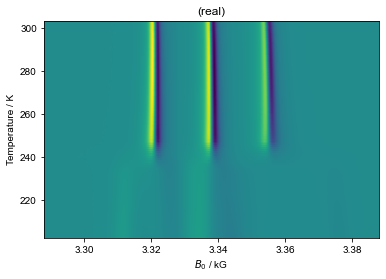

In [5]:
d_cooling = find_file("241210_TS_isooct_W20_20mM_run1.DSC", exp_type="francklab_esr/romana") #cooling
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()

I'm having error to plot. Then using chat GPT I found duplicate on data.

In [6]:
temp_values = d_cooling.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)

d_cooling_a = d_cooling["Temperature",0:49]
d_cooling_b = d_cooling["Temperature",50:]
d_cooling = concat([d_cooling_a, d_cooling_b],"Temperature")
# print("3",d_cooling)
temp_values = d_cooling.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("4",temp_values)
print("5. Duplicates in Temperature axis:", duplicates)

1 [202.715 203.91  204.759 206.154 206.702 207.824 208.942 209.706 210.789
 211.709 213.672 213.701 215.264 215.798 216.935 218.126 219.085 219.685
 221.11  221.72  222.713 224.619 224.803 226.25  227.609 227.791 229.45
 230.076 231.228 232.542 233.59  234.416 234.704 235.734 236.924 237.553
 239.147 239.663 241.304 241.953 243.329 243.935 244.877 246.299 246.58
 247.703 249.038 249.93  251.299 252.916 252.916 254.014 255.519 255.532
 257.664 257.901 259.986 260.248 260.692 262.353 262.861 264.411 264.853
 265.851 267.16  267.78  268.593 270.125 271.228 272.148 273.051 274.042
 275.554 275.922 276.926 278.475 279.389 280.024 280.811 281.978 282.815
 284.133 284.564 286.399 286.665 288.675 289.003 290.669 291.009 292.268
 293.351 293.703 294.885 295.89  297.471 298.185 298.836 300.487 301.586
 301.636 302.934]
2. Duplicates in Temperature axis: [252.916]
4 [202.715 203.91  204.759 206.154 206.702 207.824 208.942 209.706 210.789
 211.709 213.672 213.701 215.264 215.798 216.935 218.126 21

1 [202.715 203.91  204.759 206.154 206.702 207.824 208.942 209.706 210.789
 211.709 213.672 213.701 215.264 215.798 216.935 218.126 219.085 219.685
 221.11  221.72  222.713 224.619 224.803 226.25  227.609 227.791 229.45
 230.076 231.228 232.542 233.59  234.416 234.704 235.734 236.924 237.553
 239.147 239.663 241.304 241.953 243.329 243.935 244.877 246.299 246.58
 247.703 249.038 249.93  251.299 252.916 254.014 255.519 255.532 257.664
 257.901 259.986 260.248 260.692 262.353 262.861 264.411 264.853 265.851
 267.16  267.78  268.593 270.125 271.228 272.148 273.051 274.042 275.554
 275.922 276.926 278.475 279.389 280.024 280.811 281.978 282.815 284.133
 284.564 286.399 286.665 288.675 289.003 290.669 291.009 292.268 293.351
 293.703 294.885 295.89  297.471 298.185 298.836 300.487 301.586 301.636
 302.934]


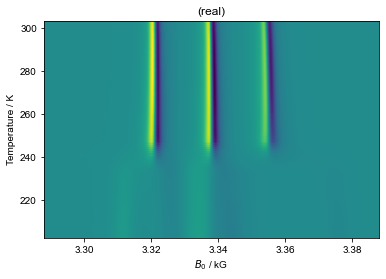

In [7]:
d_cooling.pcolor()
d_cooling.reorder('Temperature').sort('Temperature')
temp_values = d_cooling.getaxis('Temperature')
print("1",temp_values)

## Check field ranges for the three lines

<!-- let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits
 -->
<!-- RS: I will set above 260 K and below 260 K -->

## Cooling 

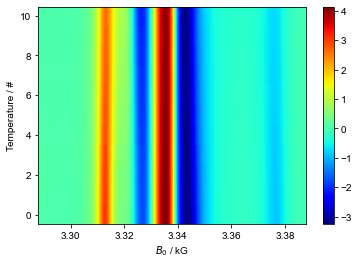

In [80]:
# figure(dpi=300)
d_cooling['Temperature':(200,230)]

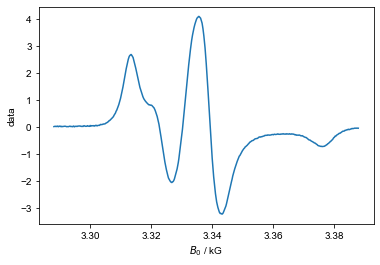

In [13]:
# figure(dpi=300)
d_cooling['Temperature':(229)]

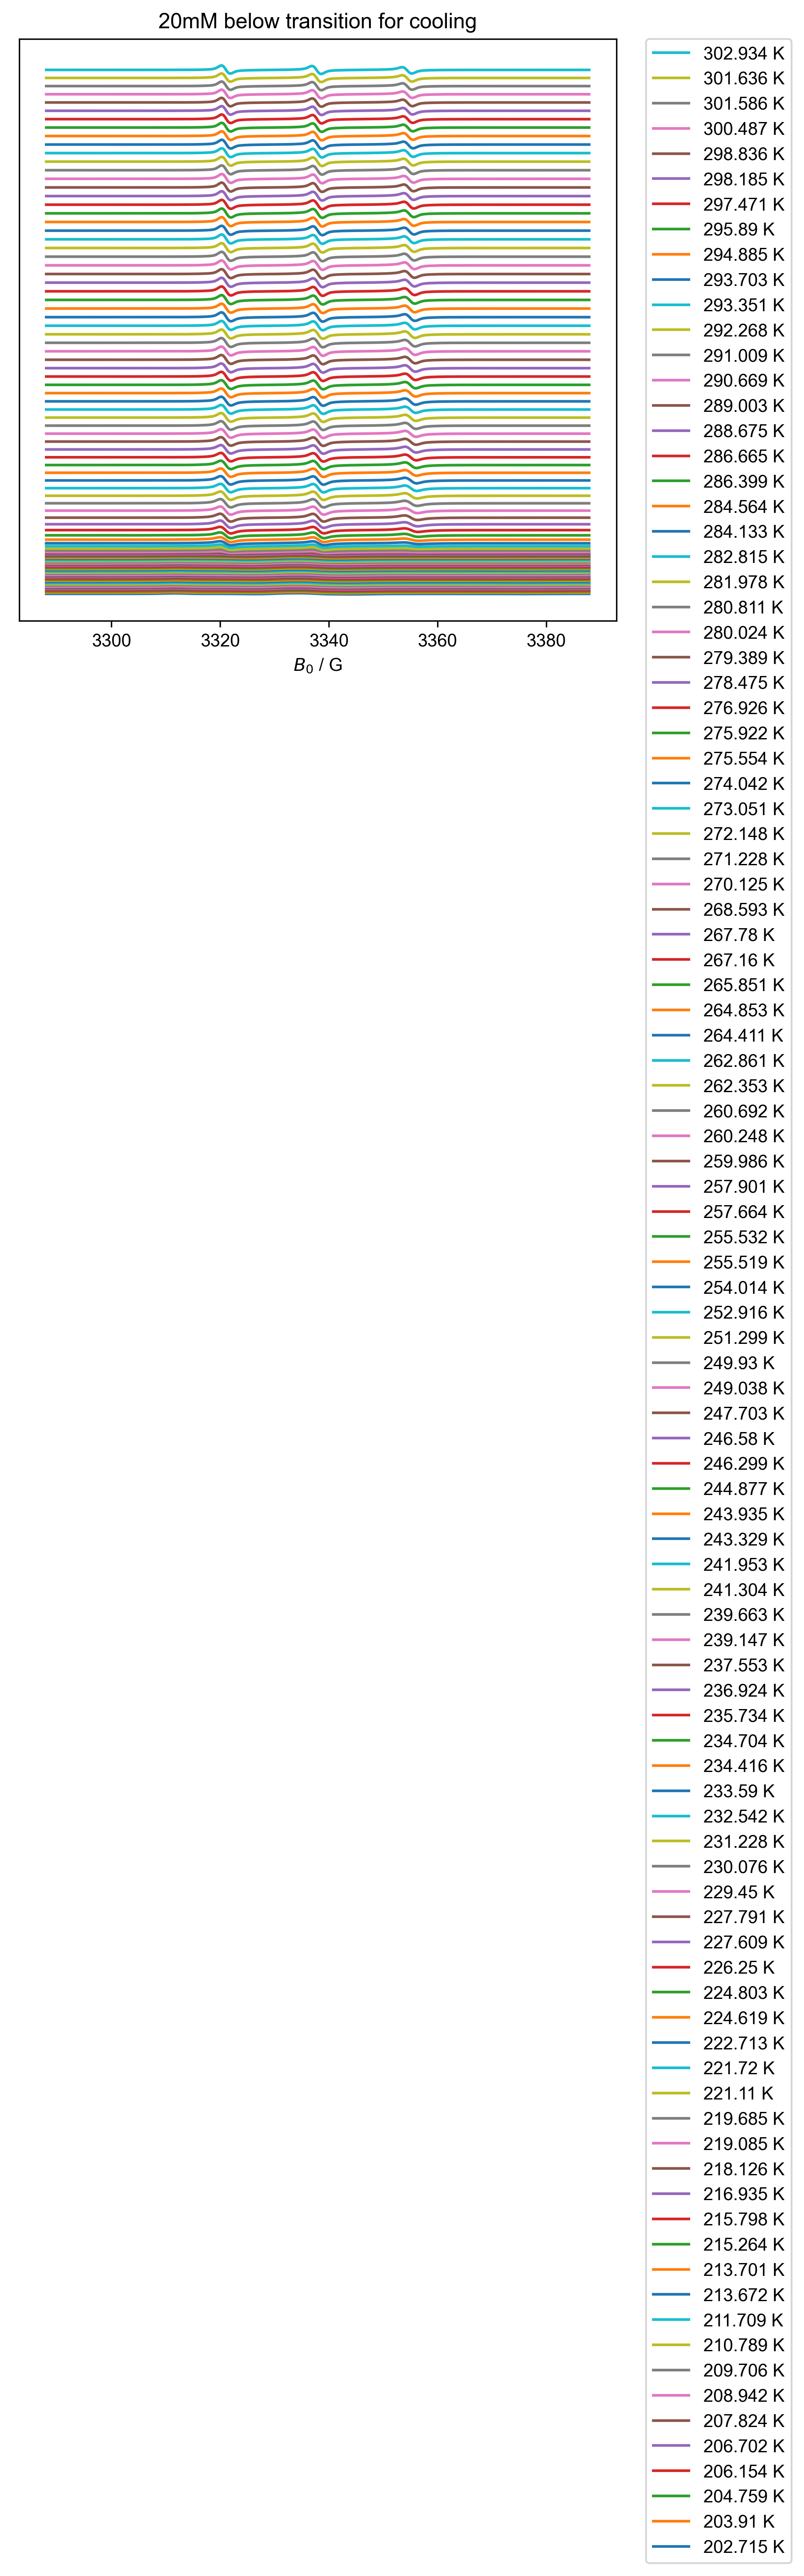

In [9]:
#cooling same plot in offset
offset= 0
d_cooling.sort("Temperature")  # Sort the data along the Temperature axis

for this_label, temp_range in [
    ("20mM below transition for cooling", (200, 350))
 ]:
    this_d1 = d_cooling["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.8
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

In [15]:
# figure(dpi=300)
# d_cooling['Temperature':(None,260)]

RS: For above transition, the fields are

Text(0.5, 1.0, 'peak C')

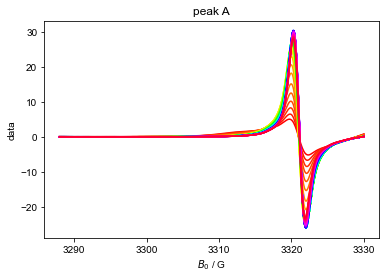

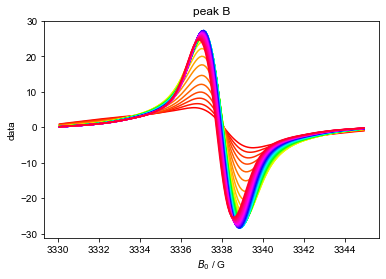

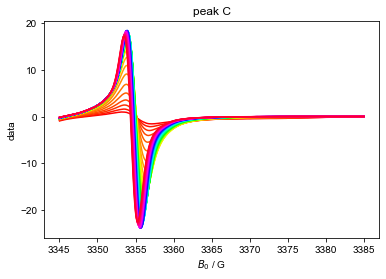

In [12]:
figure()
plot(d_cooling['Temperature':(238,None)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_cooling['Temperature':(238,None)]['$B_0$':(3330,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_cooling['Temperature':(238,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

RS: for intermidate transition the fields are

Text(0.5, 1.0, 'peak C')

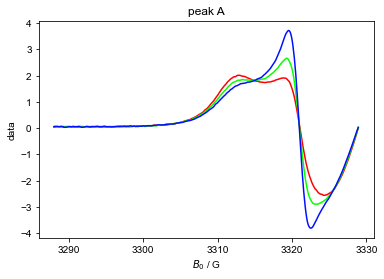

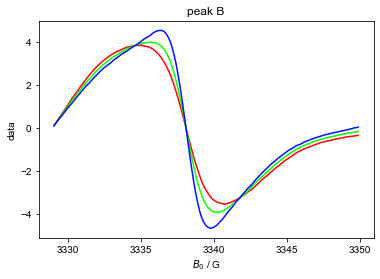

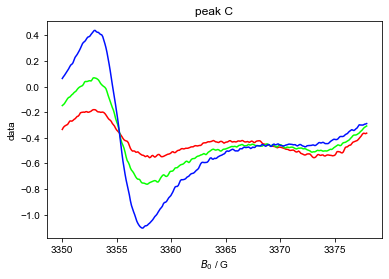

In [36]:
# RS: for intermediate transitions fields 
figure()
plot(d_cooling['Temperature':(235,238)]['$B_0$':(3285,3329)]) # peak A intermediate transition
title("peak A")
figure()
plot(d_cooling['Temperature':(235, 238)]['$B_0$':(3329,3350)]) # peak B intermediate transition
title("peak B")
figure()
plot(d_cooling['Temperature':(235, 238)]['$B_0$':(3350,3378)]) # peak C intermediate transition
title("peak C")

RS: for below transition the fields are

Text(0.5, 1.0, 'peak C')

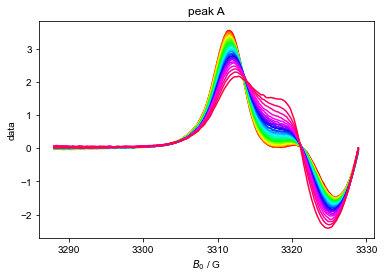

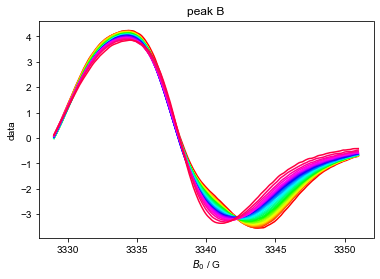

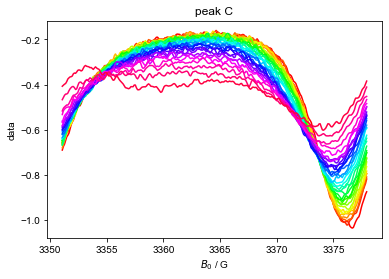

In [26]:
# RS: for below transitions fields 
figure()
plot(d_cooling['Temperature':(None,235)]['$B_0$':(3285,3329)]) # peak A below transition
title("peak A")
figure()
plot(d_cooling['Temperature':(None,235)]['$B_0$':(3329,3351)]) # peak B below transition
title("peak B")
figure()
plot(d_cooling['Temperature':(None,235)]['$B_0$':(3351,3378)]) # peak C below transition
title("peak C")

# Pick the Peaks and Calculate the Correlation times

The first cell here only operates over a limited temperature range.

#### RS: All transition 

correlation time is 1.3898413124246281e-08 for temperature 202.715
correlation time is 1.3824289780338251e-08 for temperature 203.91
correlation time is 1.399852571560415e-08 for temperature 204.759
correlation time is 1.405321739788334e-08 for temperature 206.154
correlation time is 1.400117386893425e-08 for temperature 206.702
correlation time is 1.4037439353730542e-08 for temperature 207.824
correlation time is 1.3892546222486159e-08 for temperature 208.942
correlation time is 1.3961307830324085e-08 for temperature 209.706
correlation time is 1.4150889495183097e-08 for temperature 210.789
correlation time is 1.3998541275329235e-08 for temperature 211.709
correlation time is 1.4043720438462552e-08 for temperature 213.672
correlation time is 1.390390008140455e-08 for temperature 213.701
correlation time is 1.3972994207955402e-08 for temperature 215.264
correlation time is 1.3940181693205146e-08 for temperature 215.798
correlation time is 1.3974413013791545e-08 for temperature 216.935


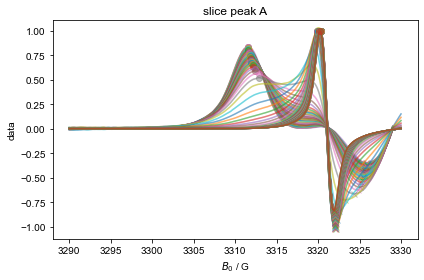

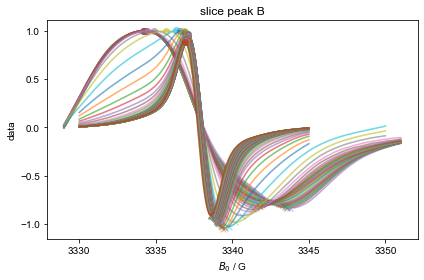

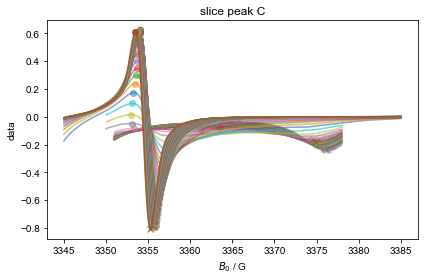

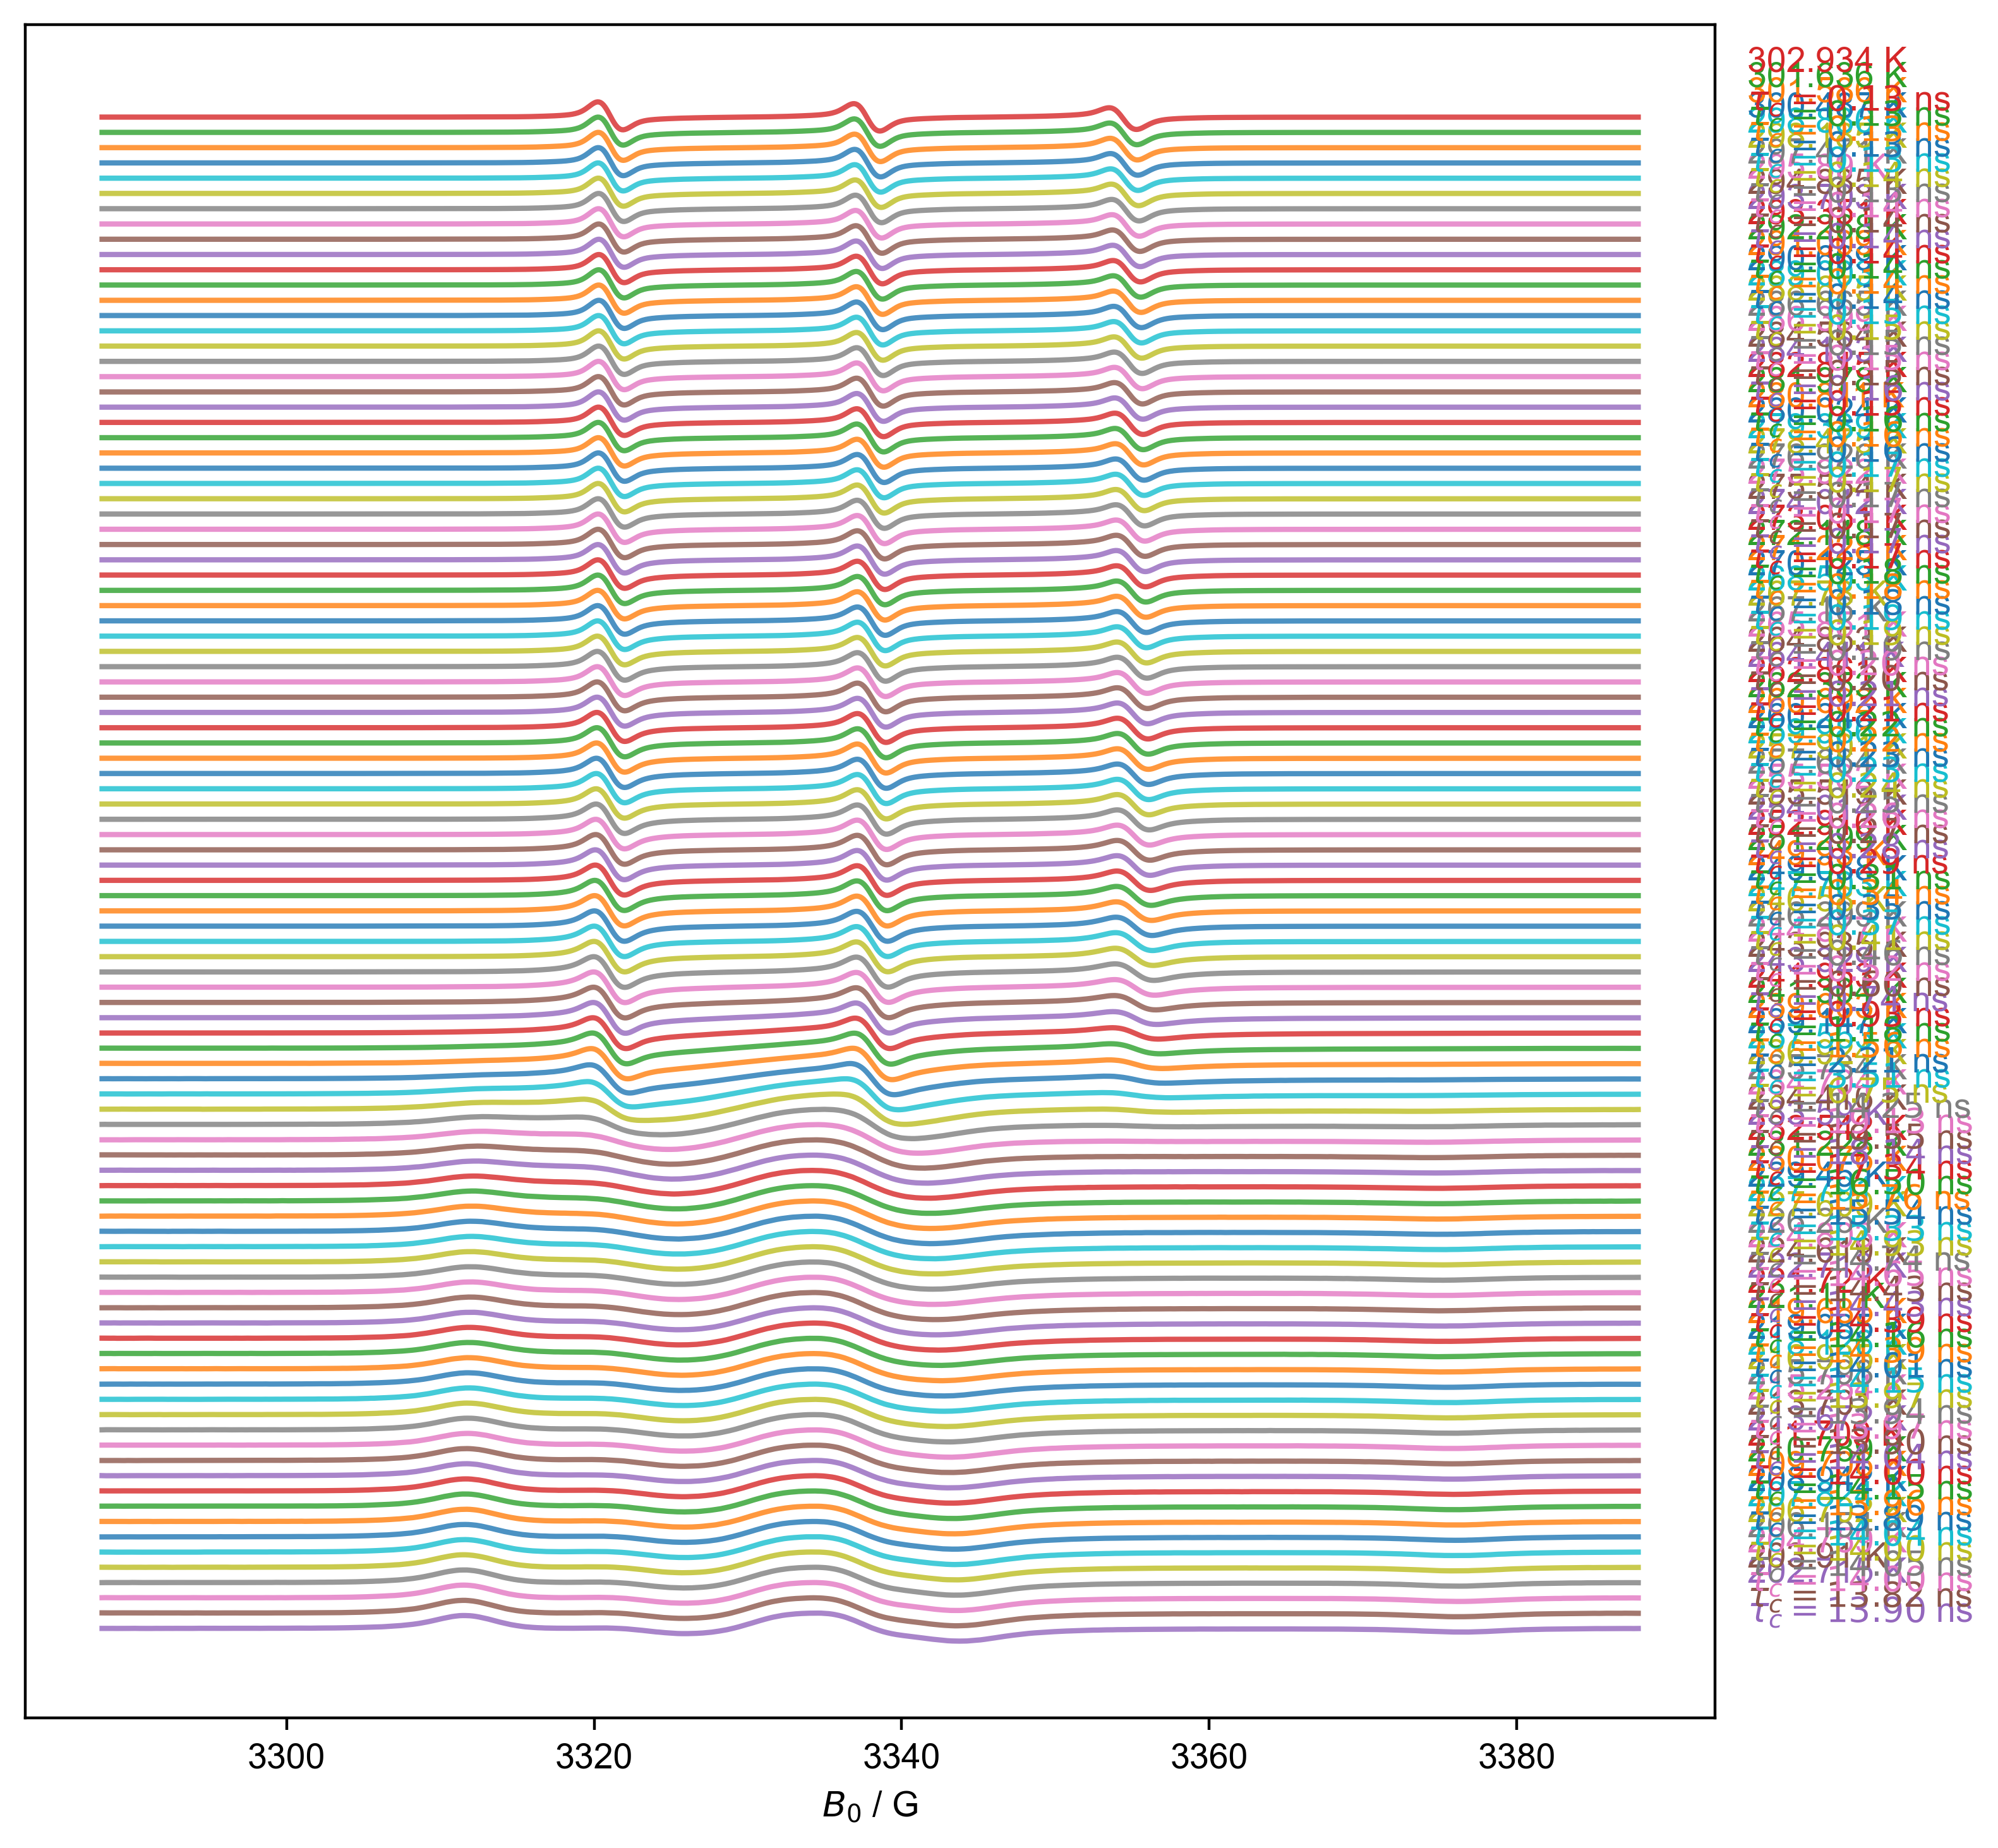

In [38]:
correlation_time_cooling = {}

all_data= d_cooling['Temperature':(None, None)] 
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 238:
            peak_A_range = (3290, 3330)
            peak_B_range = (3330, 3345)
            peak_C_range = (3345, 3385)
        elif this_temp >= 235:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3350)
            peak_C_range = (3350,3378)        
        else:
            peak_A_range = (3290, 3329)
            peak_B_range = (3329, 3351)
            peak_C_range = (3351, 3378)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(8,12/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c, "for temperature", this_temp)
        correlation_time_cooling[label_str] = tau_c 
        plt.gca().text(
                3395,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.2f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1
        #xlim(3375,3550)
        j_counter += 1.1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [39]:
correlation_time_cooling

{'202.715': 1.3898413124246281e-08,
 '203.91': 1.3824289780338251e-08,
 '204.759': 1.399852571560415e-08,
 '206.154': 1.405321739788334e-08,
 '206.702': 1.400117386893425e-08,
 '207.824': 1.4037439353730542e-08,
 '208.942': 1.3892546222486159e-08,
 '209.706': 1.3961307830324085e-08,
 '210.789': 1.4150889495183097e-08,
 '211.709': 1.3998541275329235e-08,
 '213.672': 1.4043720438462552e-08,
 '213.701': 1.390390008140455e-08,
 '215.264': 1.3972994207955402e-08,
 '215.798': 1.3940181693205146e-08,
 '216.935': 1.3974413013791545e-08,
 '218.126': 1.4148256758444145e-08,
 '219.085': 1.4010782254059478e-08,
 '219.685': 1.438900948039938e-08,
 '221.11': 1.4159533221364446e-08,
 '221.72': 1.4390373682552974e-08,
 '222.713': 1.4429828821920939e-08,
 '224.619': 1.4434947673100943e-08,
 '224.803': 1.4649628043873265e-08,
 '226.25': 1.4735422408378603e-08,
 '227.609': 1.492971898481811e-08,
 '227.791': 1.532942814404679e-08,
 '229.45': 1.554479296899558e-08,
 '230.076': 1.576167013449186e-08,
 '231.

In [40]:
temp_cooling= np.array([float(j) for j in correlation_time_cooling.keys()])
tau_cooling = np.array(list(correlation_time_cooling.values()))

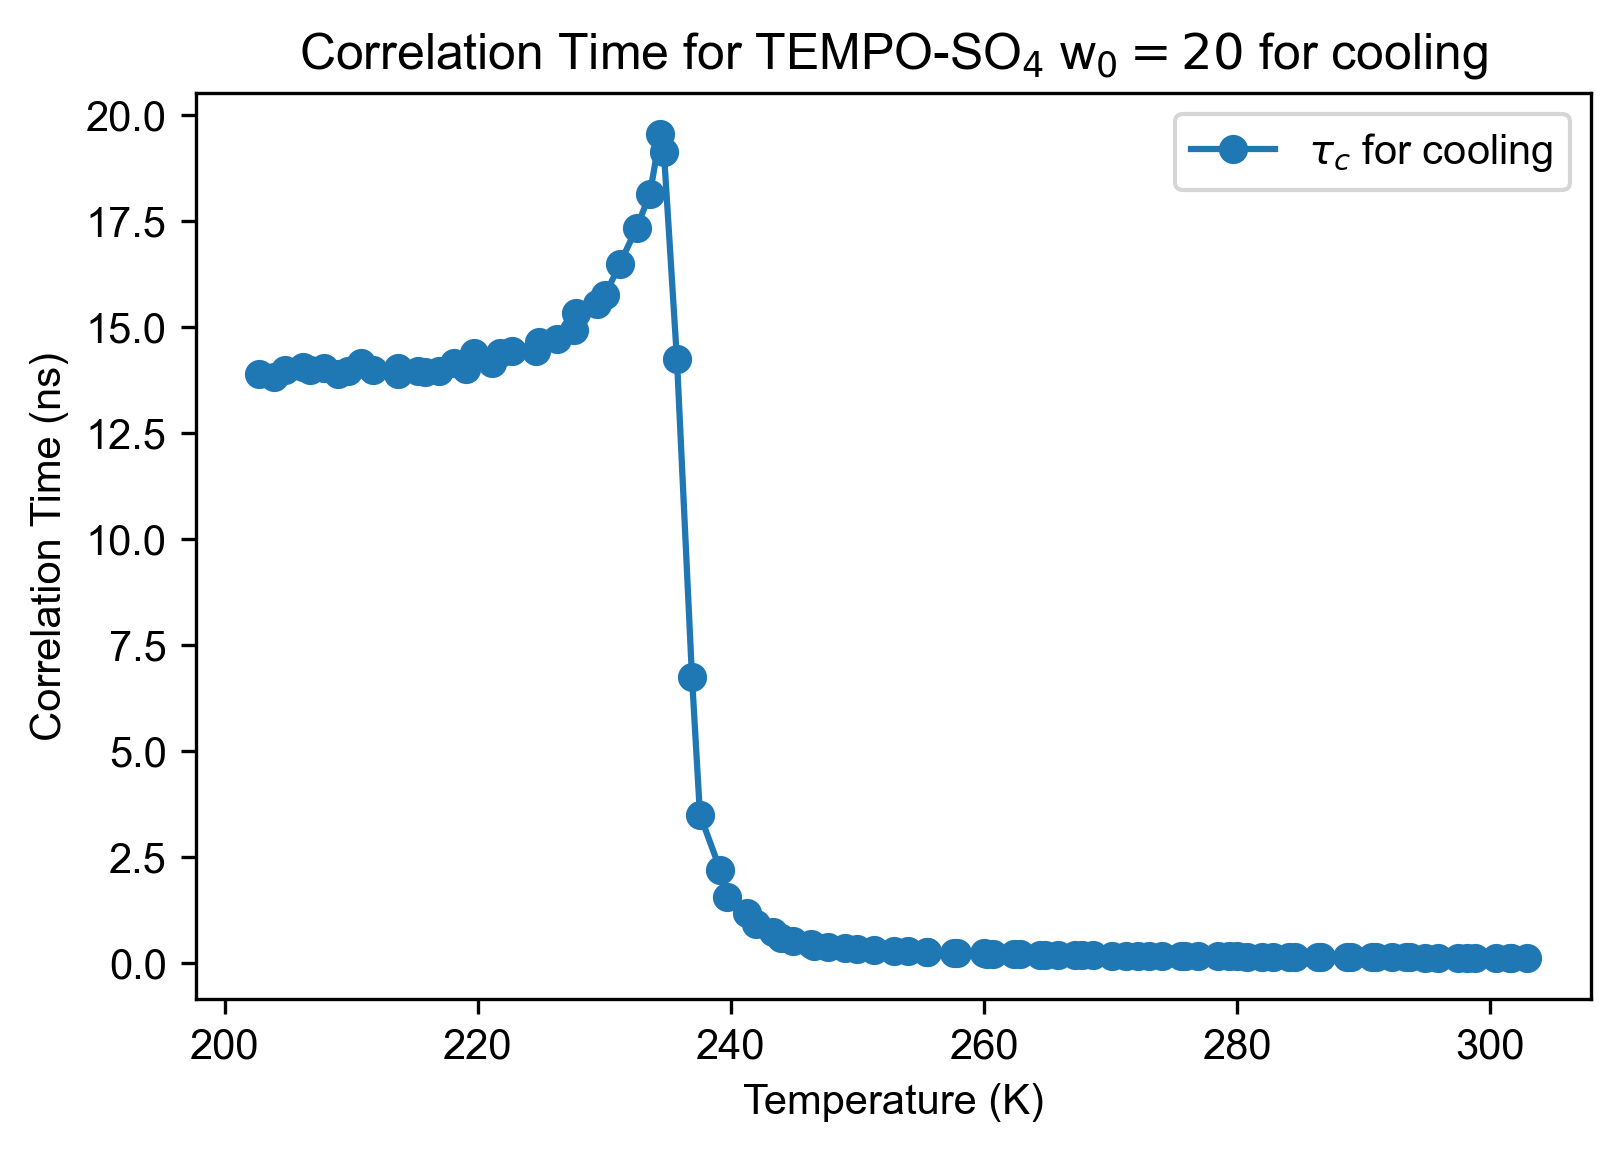

In [41]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ for cooling')
show()

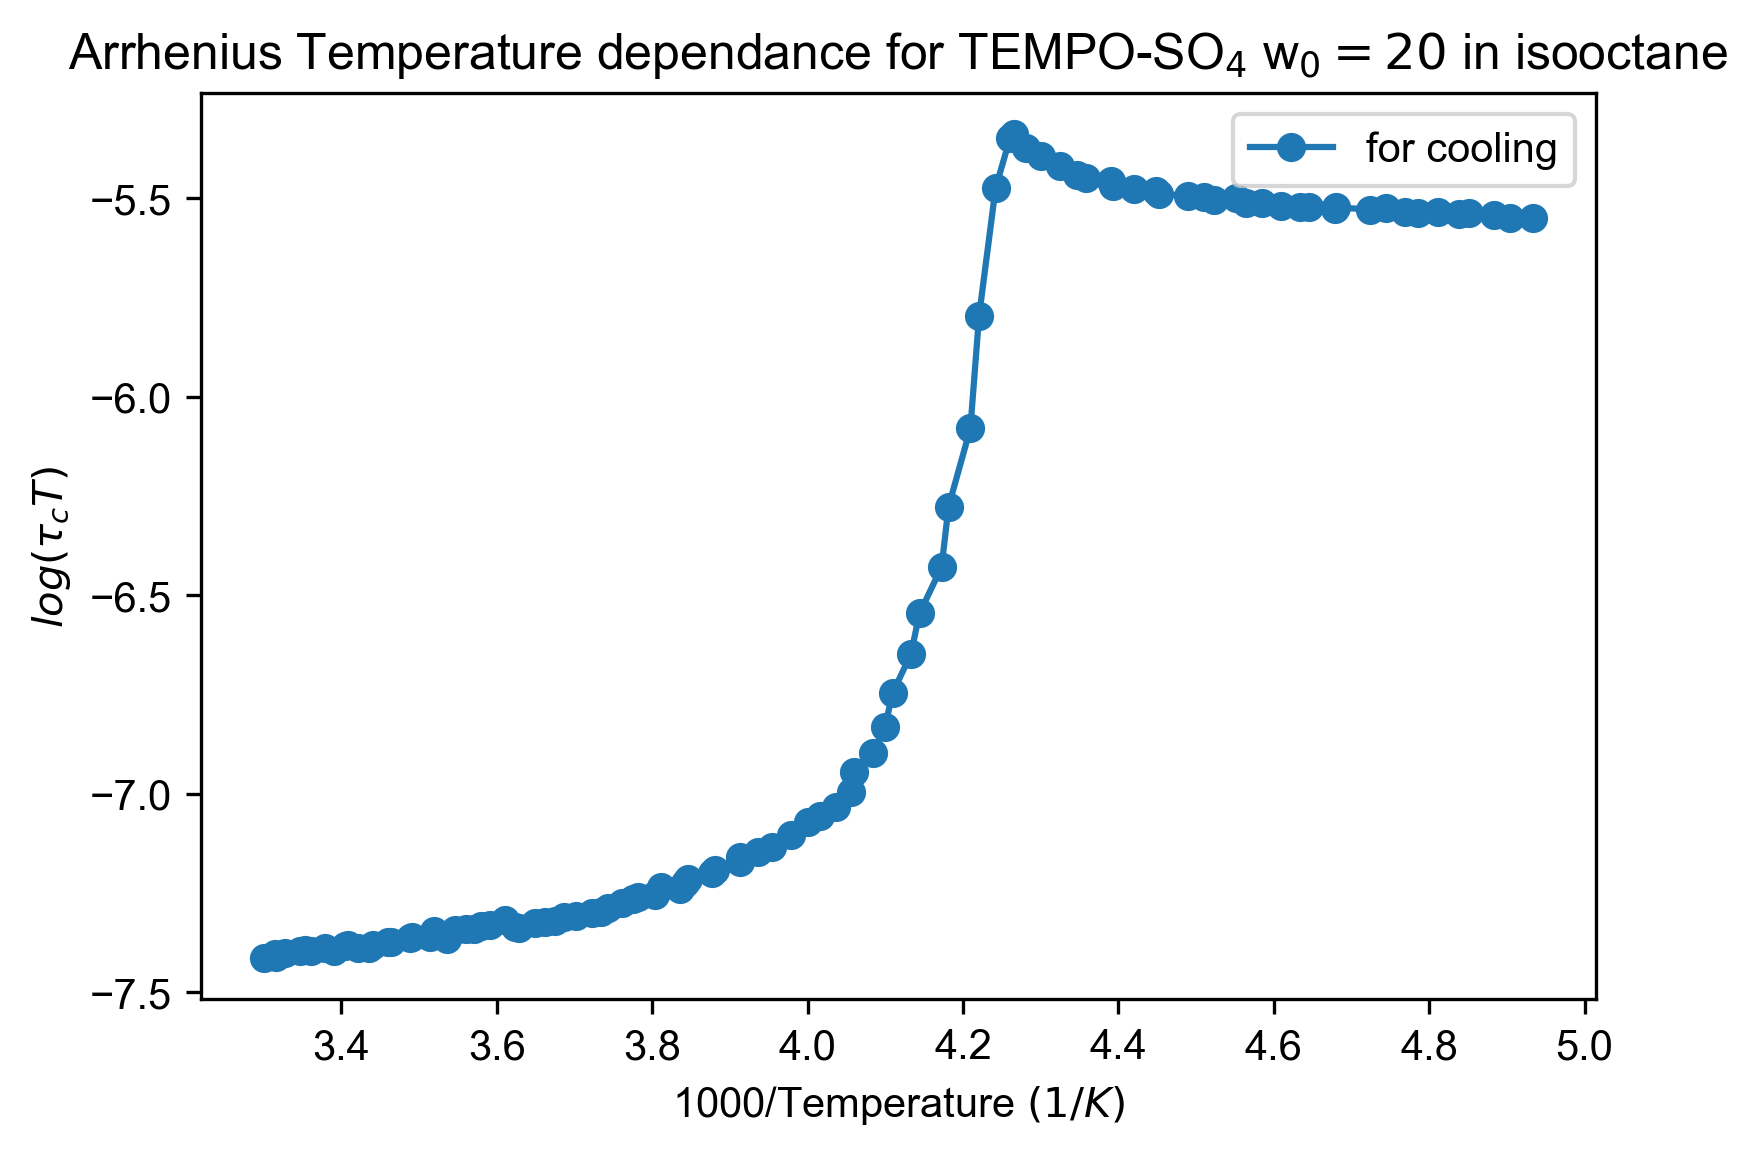

In [42]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()

<!-- #### RS: Below transition  -->

<!-- all_data= d_cooling['Temperature':(None,260)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time_below={}
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3375,3395)
        elif this_temp >= 253:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3387,3404)
        else:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3382,3406)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_below[label_str] = tau_c 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('below transition for cooling TEMPO-SO$_4$ w$_0=20$ in isooctane')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False) -->

<!-- # correlation_time_below -->

<!-- # temp= [float(temp) for temp in correlation_time_below.keys()]
# tau_below= list(correlation_time_below.values())
# figure(dpi=300, figsize=(8,6))
# tau_ns_below = [t / 1e-9 for t in tau_below]
# plot(temp, tau_ns_below, linestyle='-',  marker='o', label=r"$\tau_c$")
# legend()
# xlabel('Temperature (K)')
# ylabel('Correlation Time (ns)')
# title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
# show() -->

## Reheating 

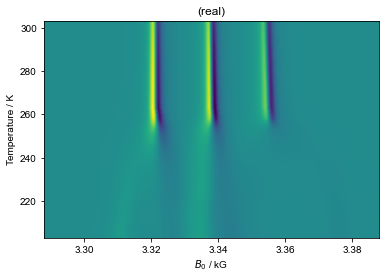

In [43]:
d_reheating = find_file("241210_TS_isooct_W20_20mM_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating= d_reheating.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_reheating.reorder('Temperature').sort('Temperature')
d_reheating.pcolor()

In [44]:
temp_values = d_reheating.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)

1 [202.97  203.403 204.64  206.139 206.554 208.236 209.192 209.574 211.213
 212.059 212.175 213.004 215.278 216.158 217.266 217.294 219.257 219.885
 220.967 221.593 222.217 223.519 224.746 225.871 227.273 228.056 228.558
 230.215 231.172 231.518 233.121 233.135 234.498 235.555 237.252 238.275
 238.875 239.174 240.016 241.574 242.777 244.366 244.447 245.655 247.169
 247.503 249.251 250.276 251.073 252.161 253.234 254.291 254.714 255.954
 257.322 257.73  259.121 260.157 261.295 262.3   262.966 264.112 264.97
 265.84  266.889 267.833 268.788 269.509 270.845 272.2   272.938 273.916
 274.907 275.656 277.067 278.019 278.744 279.86  280.076 281.916 283.261
 284.299 284.883 285.237 287.324 287.957 289.309 290.444 290.898 292.159
 293.204 293.694 294.524 296.044 297.525 297.988 299.241 299.829 301.416
 302.128 302.951]
2. Duplicates in Temperature axis: []


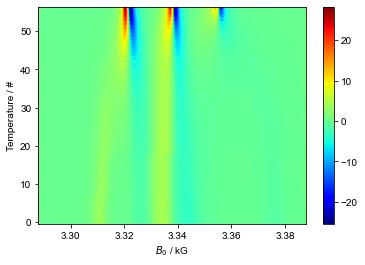

In [45]:
figure()
d_reheating['Temperature':(None,260)]

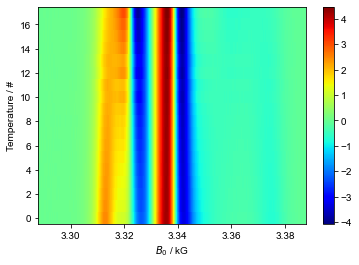

In [134]:
figure()
d_reheating['Temperature':(232,250)]

Text(0.5, 1.0, 'peak C')

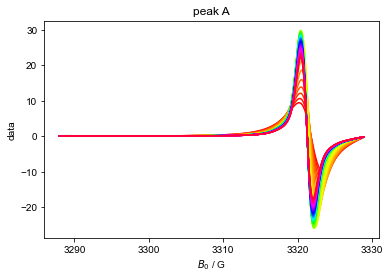

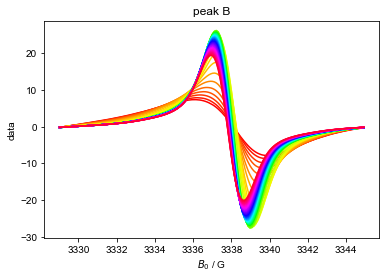

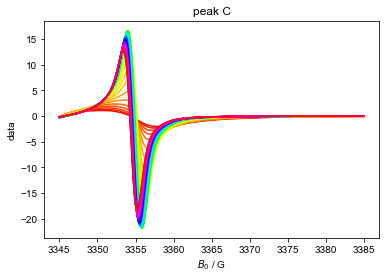

In [67]:
# RS: Above transition fields
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3285,3329)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3329,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(250,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

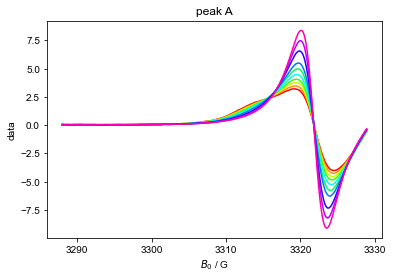

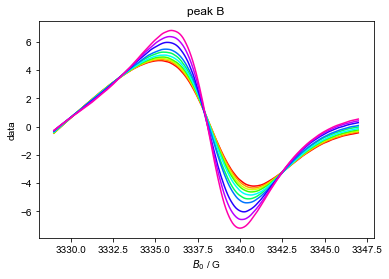

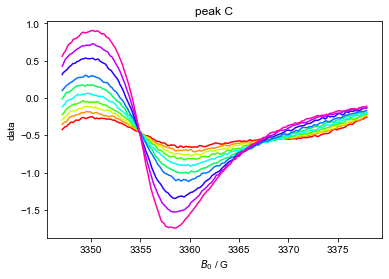

In [90]:
# RS: Intermediate 1 transition fields
figure()
plot(d_reheating['Temperature':(239,250)]['$B_0$':(3285,3329)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(239,250)]['$B_0$':(3329,3347)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(239,250)]['$B_0$':(3347,3378)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

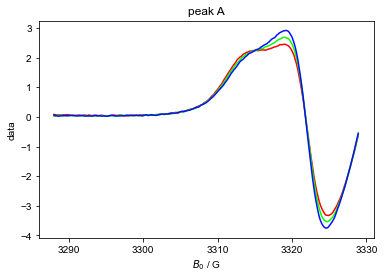

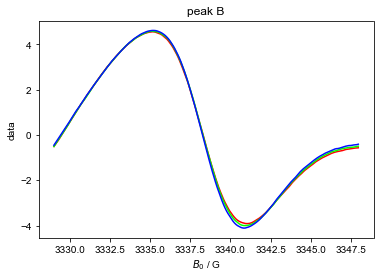

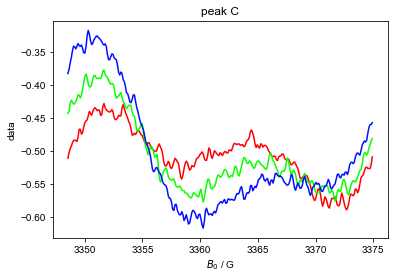

In [88]:
# RS: Intermediate 2 transition fields
figure()
plot(d_reheating['Temperature':(236,239)]['$B_0$':(3285,3329)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(236,239)]['$B_0$':(3329,3348.5)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(236,239)]['$B_0$':(3348.5,3375)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

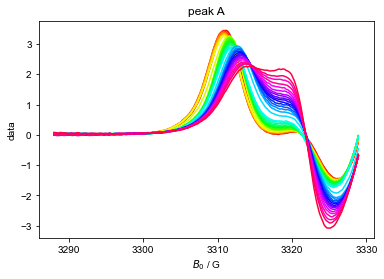

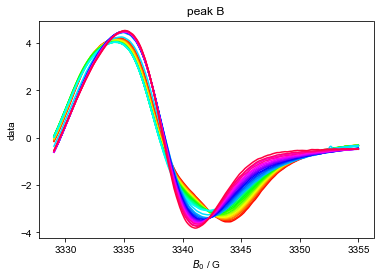

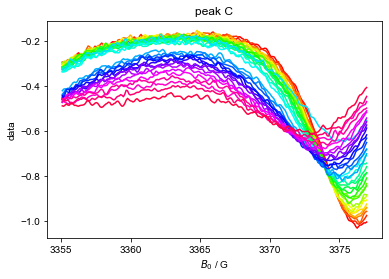

In [73]:
# RS: Below transition fields
figure()
plot(d_reheating['Temperature':(None,236)]['$B_0$':(3285,3329)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(None,236)]['$B_0$':(3329,3355)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(None,236)]['$B_0$':(3355,3377)]) # peak C above transition
title("peak C")

#### RS: All transition

correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation time is 1.2740142366228818e-10
correlation

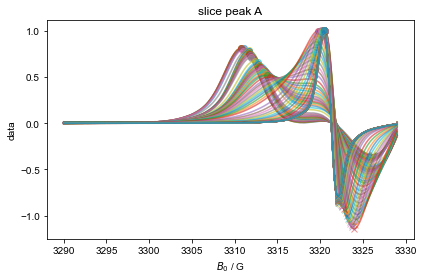

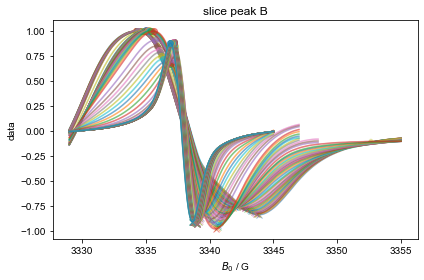

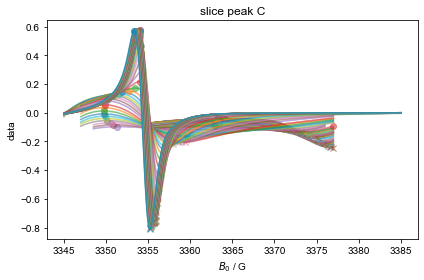

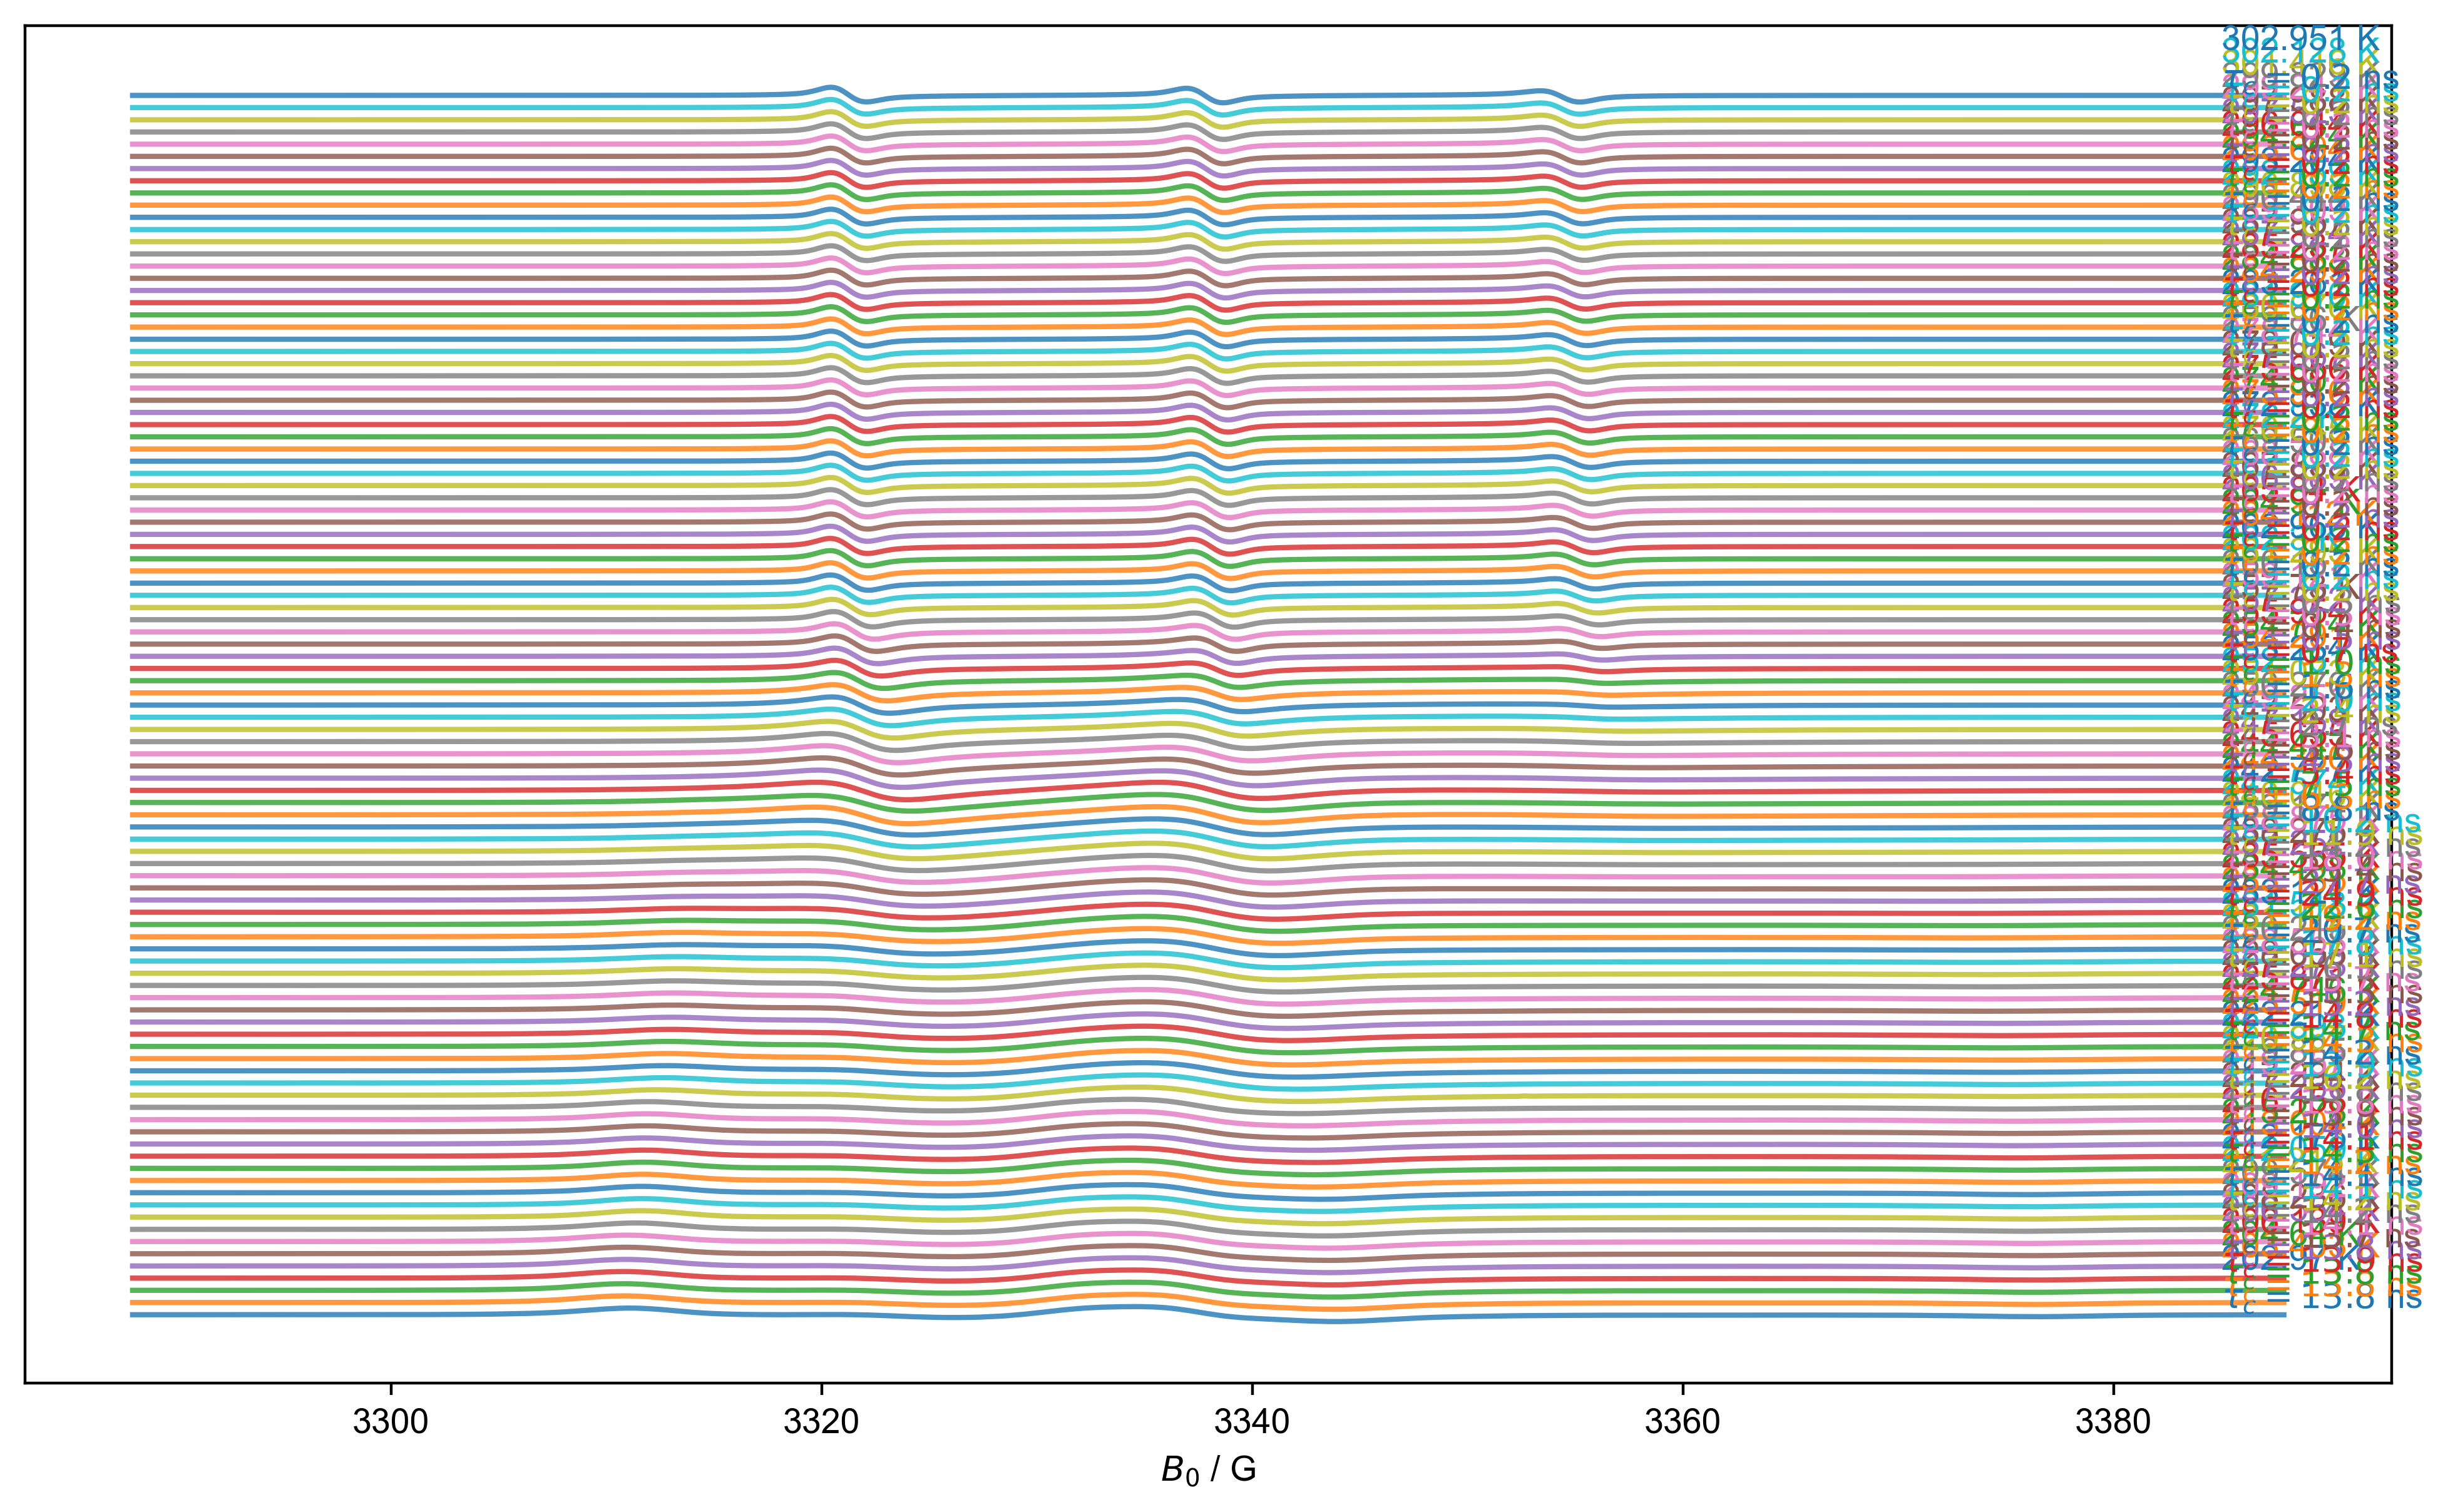

In [93]:
correlation_time_reheating = {}

all_data_reheating= d_reheating['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 250:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3345)
            peak_C_range = (3345,3385)
        elif this_temp >= 239:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3347)
            peak_C_range = (3347,3377)
        elif this_temp >= 236:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3348.5)
            peak_C_range = (3348.5,3376)
        else:
            peak_A_range = (3290,3329)
            peak_B_range = (3329,3355)
            peak_C_range = (3355,3377)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=3e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [94]:
correlation_time_reheating

{'202.97': 1.3763229799698337e-08,
 '203.403': 1.3763369543238163e-08,
 '204.64': 1.3776230222521332e-08,
 '206.139': 1.389439696967506e-08,
 '206.554': 1.381881078867307e-08,
 '208.236': 1.3693655843100206e-08,
 '209.192': 1.4135646941347738e-08,
 '209.574': 1.4217098499076598e-08,
 '211.213': 1.4172737091758422e-08,
 '212.059': 1.413816193890285e-08,
 '212.175': 1.4140594961125587e-08,
 '213.004': 1.4188549394986587e-08,
 '215.278': 1.4271968480994528e-08,
 '216.158': 1.4050819482505603e-08,
 '217.266': 1.4047623782678597e-08,
 '217.294': 1.3914967695141911e-08,
 '219.257': 1.3783097049925935e-08,
 '219.885': 1.3777846318099201e-08,
 '220.967': 1.6231143730857956e-08,
 '221.593': 1.3850550634774441e-08,
 '222.217': 1.4191879276251547e-08,
 '223.519': 1.4291328522229022e-08,
 '224.746': 1.466950826588885e-08,
 '225.871': 1.4786063850622019e-08,
 '227.273': 1.5163834480856914e-08,
 '228.056': 1.5329526437174248e-08,
 '228.558': 1.567459732105137e-08,
 '230.215': 1.633609351841026e-08,


In [95]:
temp_reheating= np.array([float(j) for j in correlation_time_reheating.keys()])
tau_reheating = np.array(list(correlation_time_reheating.values()))

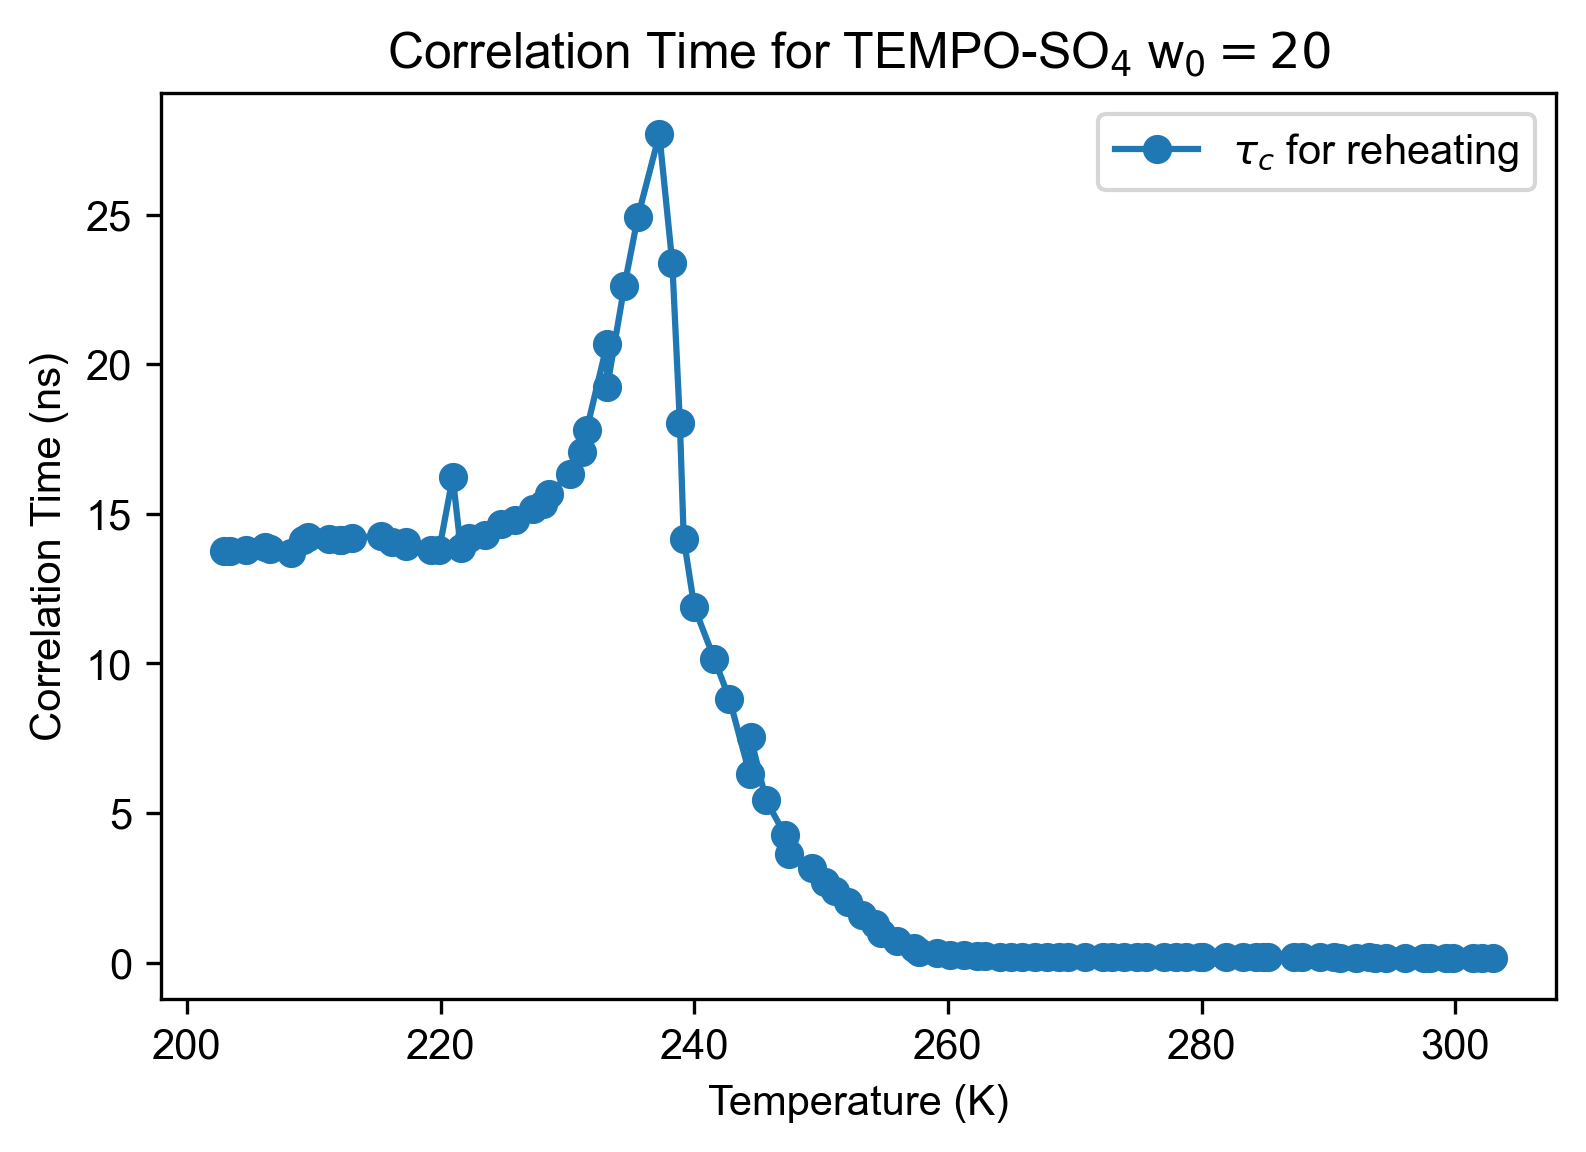

In [96]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

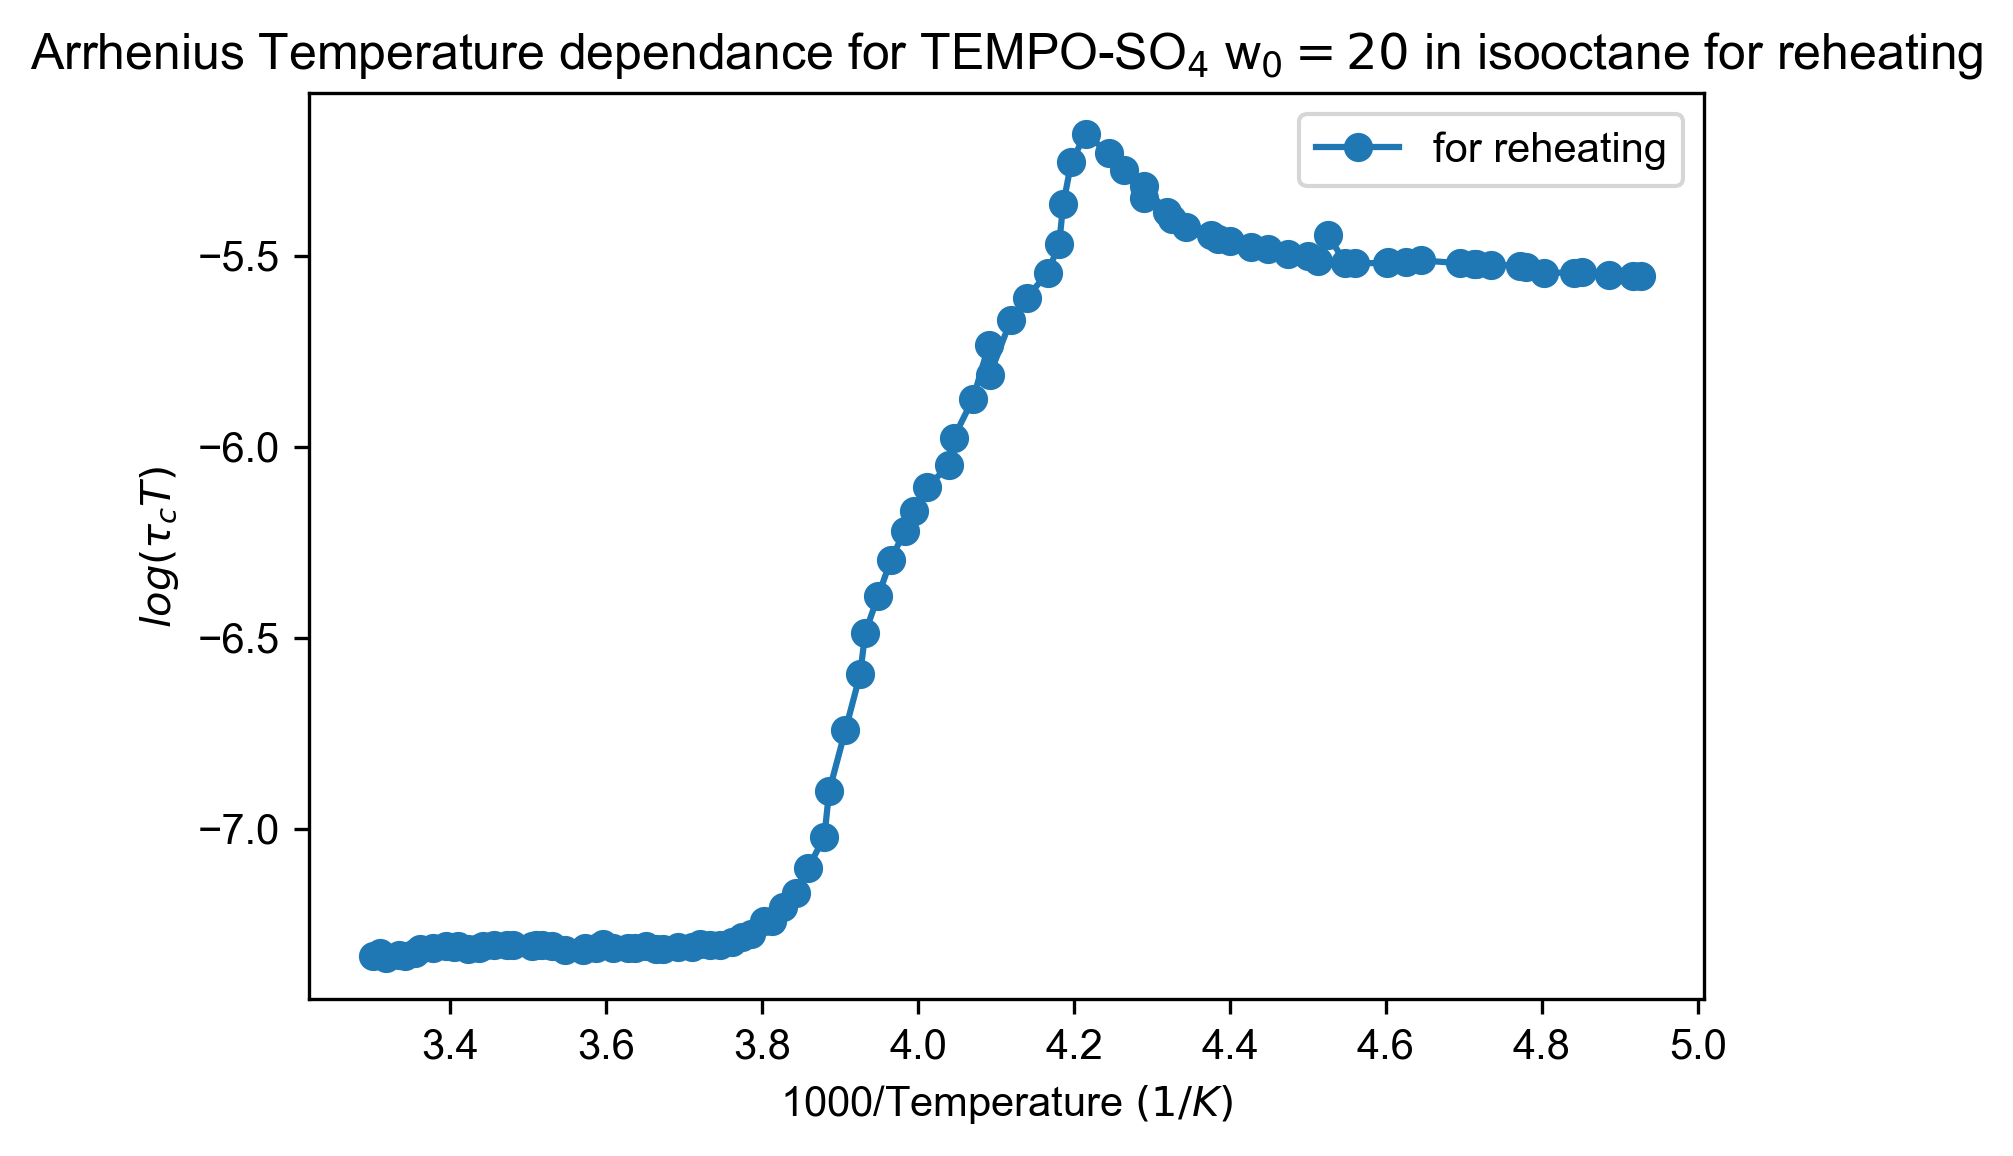

In [97]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane for reheating')
show()

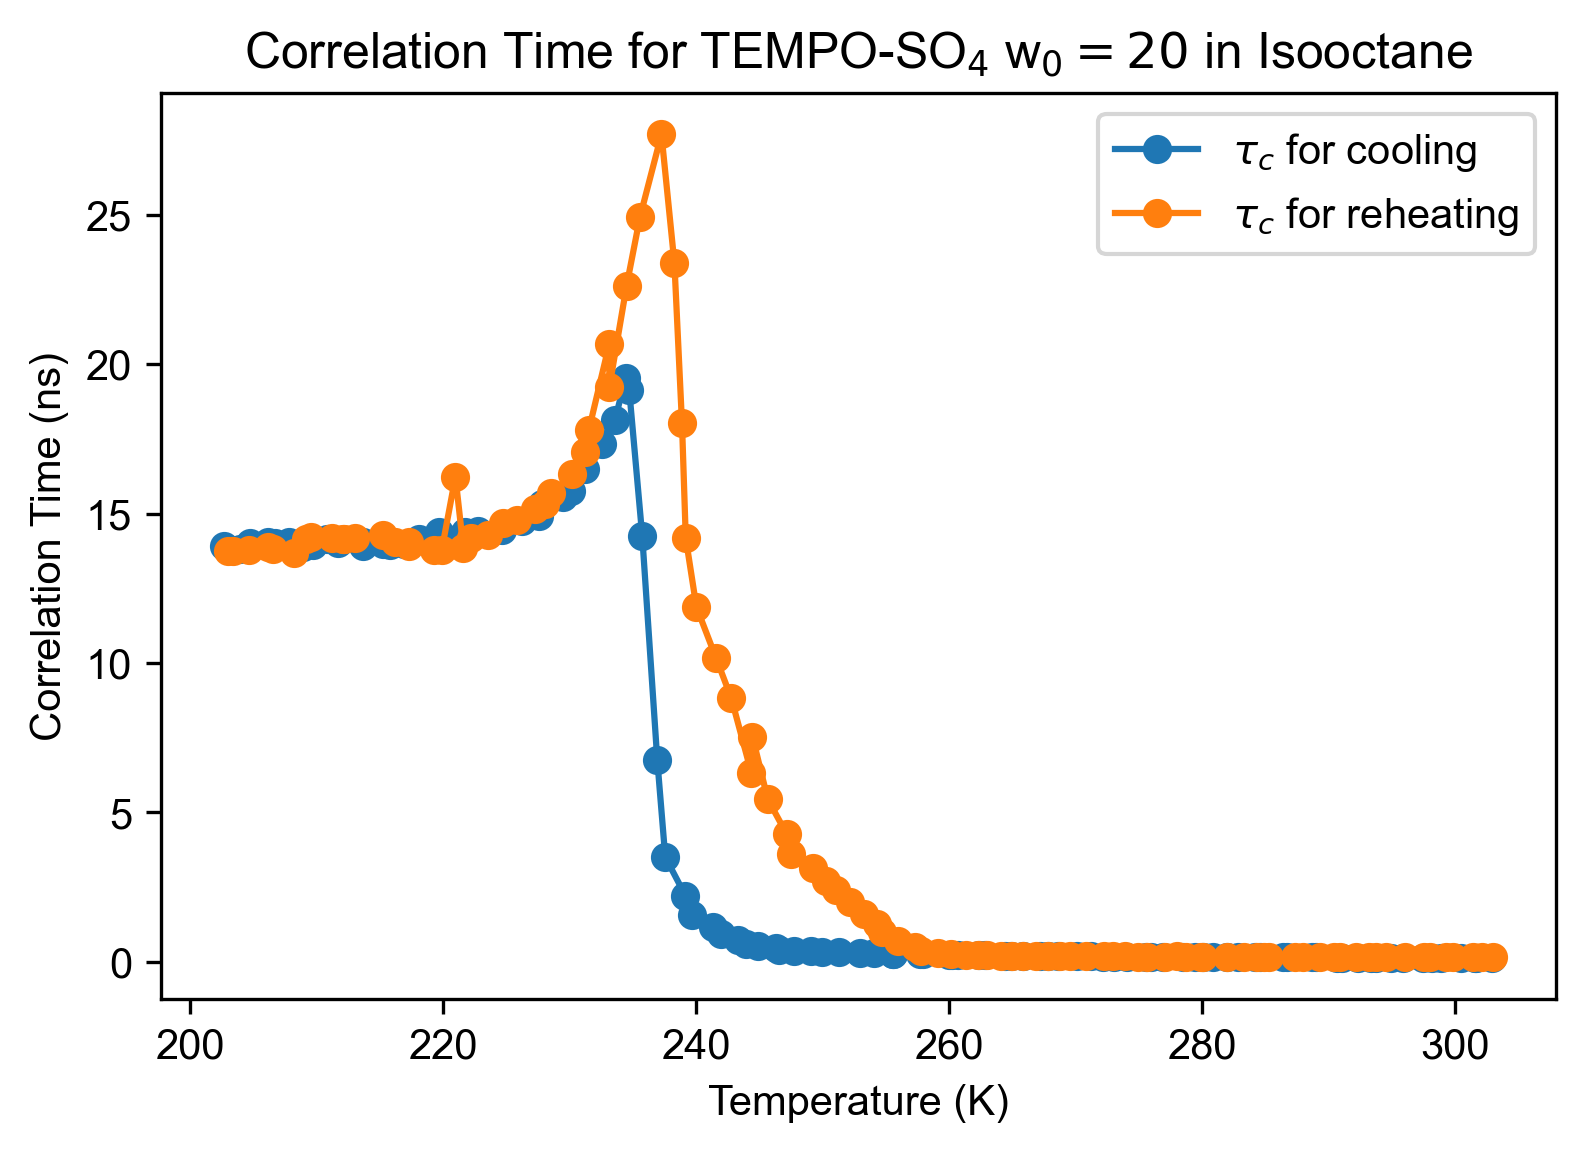

In [98]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(250,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

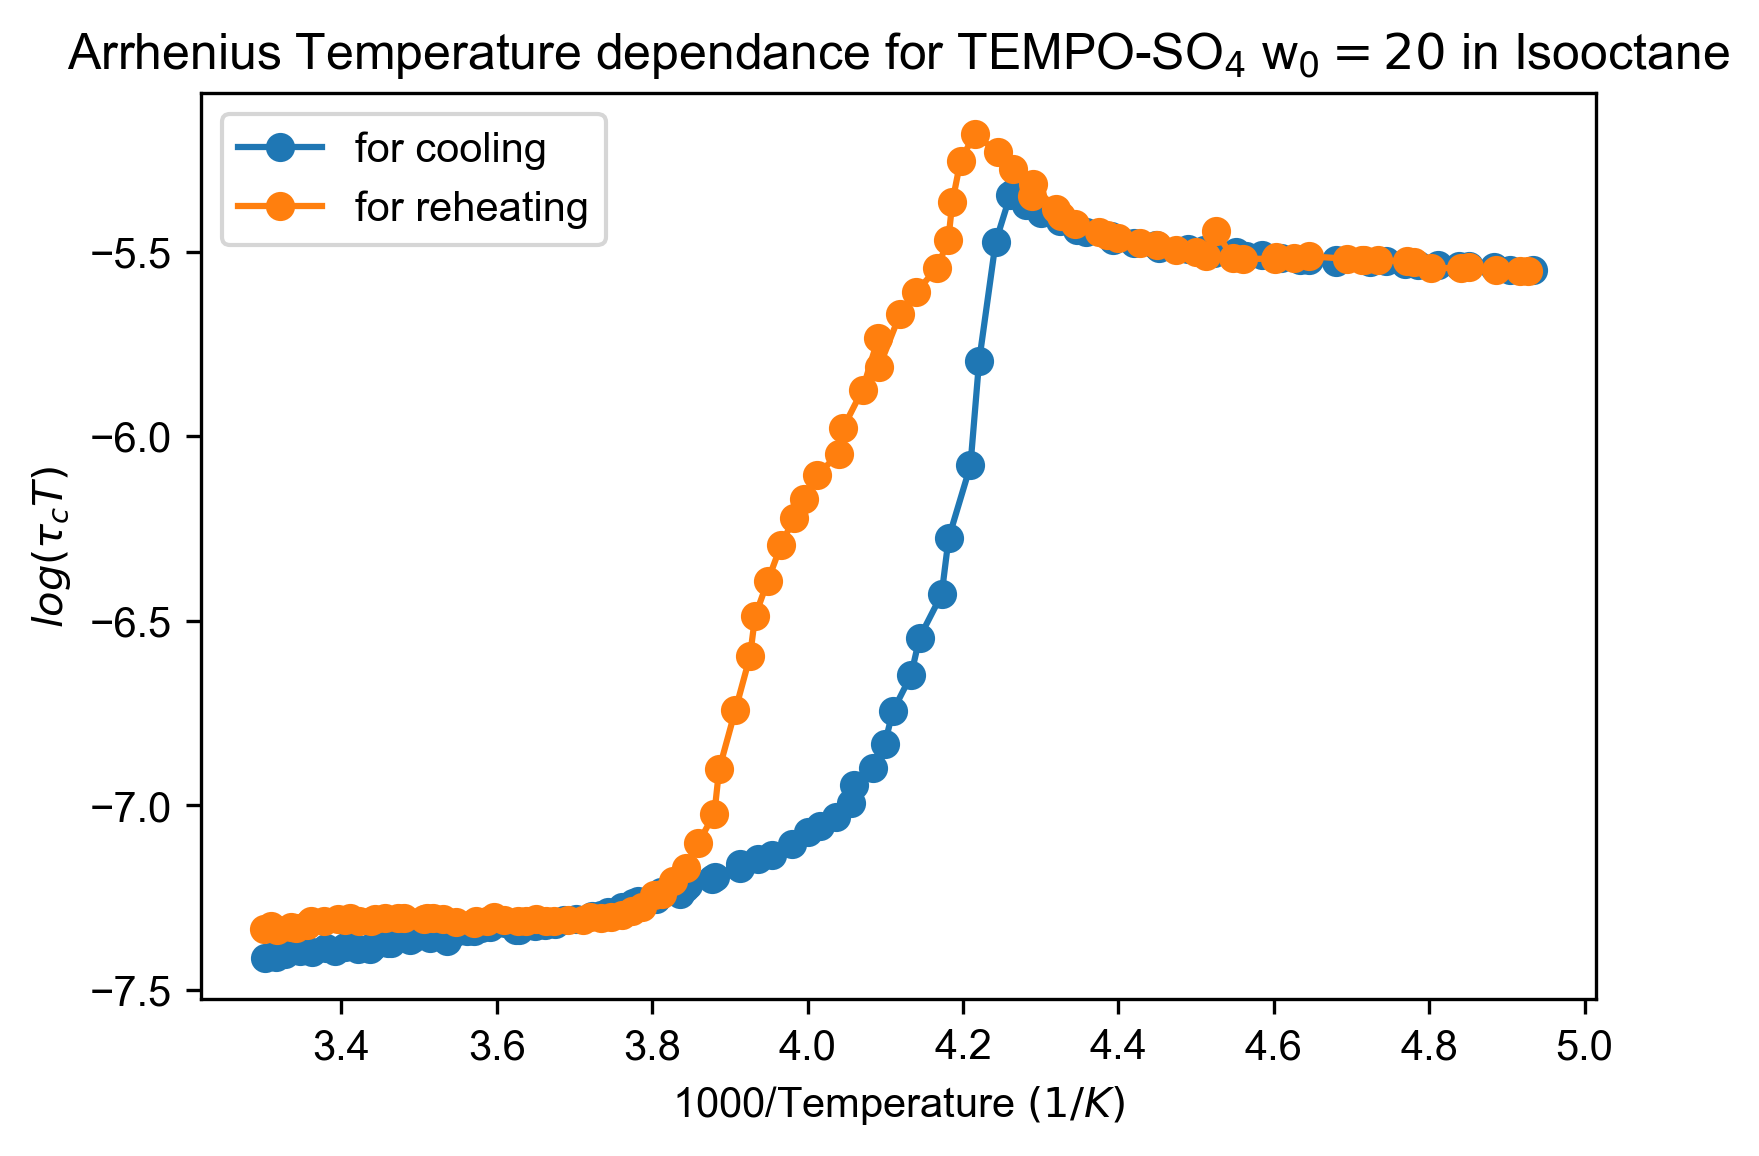

In [99]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(2.9,4.1)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

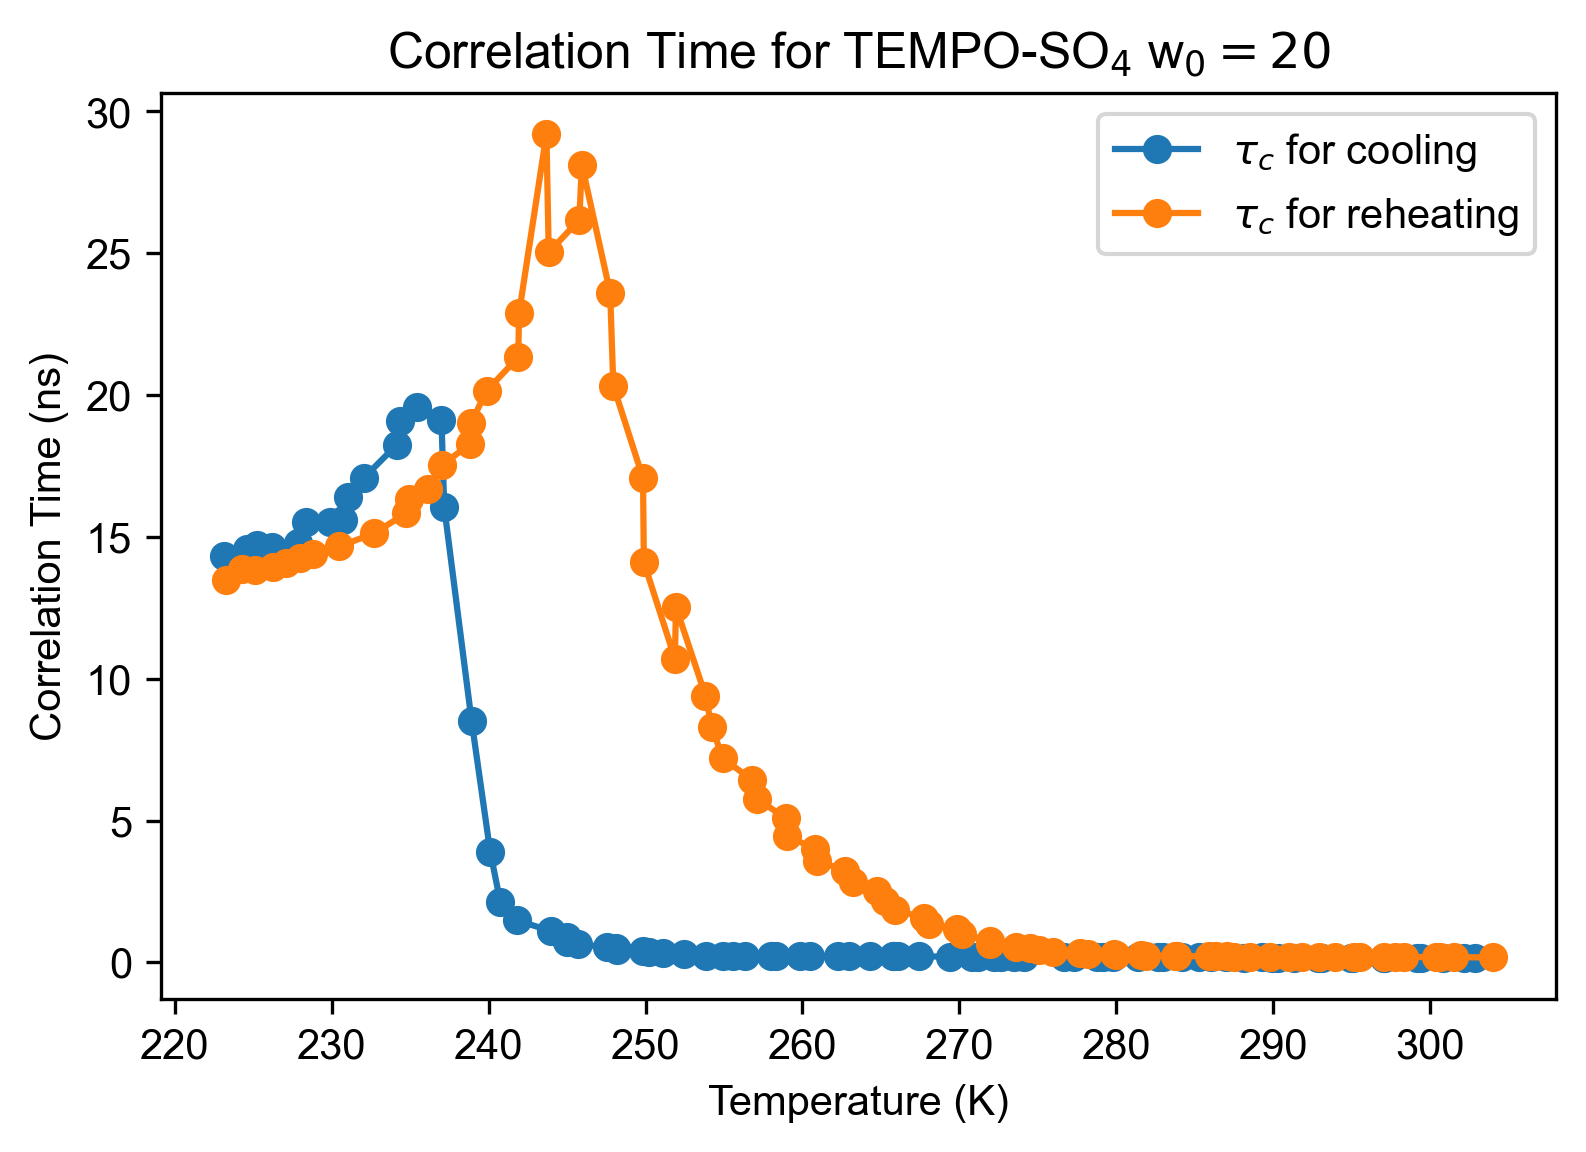

In [170]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling[4:], tau_cooling[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating[4:], tau_reheating[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

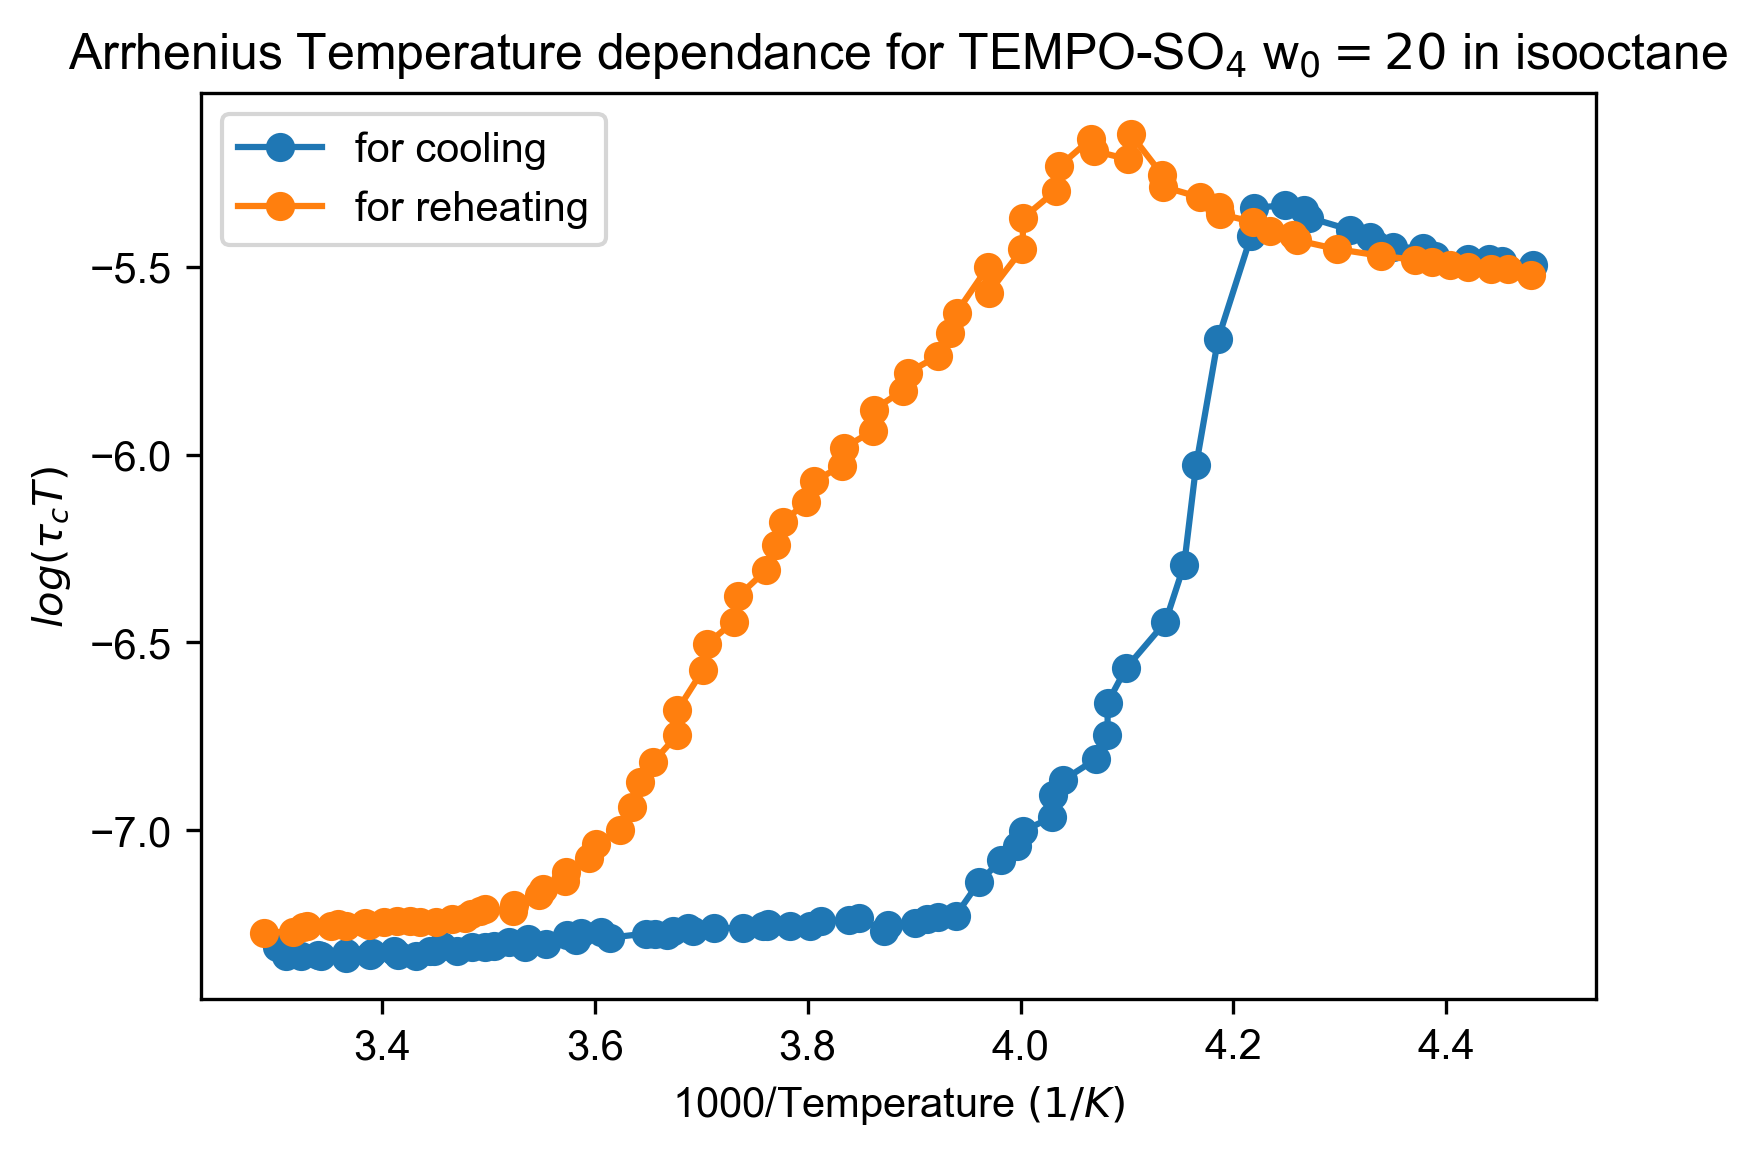

In [171]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling[4:], log10(tau_cooling[4:]*temp_cooling[4:]), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating[4:], log10(tau_reheating[4:]*temp_reheating[4:]), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(3,4)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()